# FCA-PAD: hypothesis tests for the thesis
One place that tests every claim of the thesis with a p-value, using the results the v5–v8 notebooks
already saved (nothing is retrained). Run it after v5, v6, v7 and v8 have been run for the logs you
want included.

**Every test:** paired results (one pair per detector × log × seed, or log × seed), one-sided Wilcoxon
signed-rank test, α = 0.05, Holm correction across the main family of hypotheses, mean difference with a
95% bootstrap interval.

| # | Claim | Source |
|---|---|---|
| H1 | Detectors score much higher on finding anomalies (best F1) than on recovering money | v6 |
| H2 | Detectors fill review slots with harmless decoys; the financial layer fills fewer | v6 |
| H3 | The financial layer recovers more money than the detector alone | v5 |
| H4 | Adding audit tests (F11–F15) improves the layer | v6 |
| H5 | Learned rule weights recover more money than equal weights | v8 |
| H6 | Learned rule weights follow how reliable each rule is | v7 |
| H7 | The layer still wins when detectors train on polluted data | v6 |
| H8 | The final system (learned rules × money) beats the best benchmark detector (GAMA) | v8 |
| H9 | Limitation: rules recover less on fraud they were not written for | v8 |
| E1 | Equivalence: a GAMA side lane makes no practical difference (±0.05) | v8 |


In [ ]:
# 0 · Paths
import os, re, sys, numpy as np, pandas as pd
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
BASE_ROOT = os.environ.get("FCA_ROOT", "/content/drive/MyDrive/FCA_PAD_v2" if IN_COLAB else os.path.abspath("FCA_PAD_v2"))
LOGS = ["BPIC20_D", "BPIC20_I", "BPIC20_PR", "BPIC20_R"]
OUT = f"{BASE_ROOT}/23_hypothesis_tests"; os.makedirs(OUT, exist_ok=True)
DETECTORS = ["LSTM", "GAMA", "DAE"]
K, RATIO = 50, 10
MR = f"MoneyRecall@{K}"
CASE = "case:concept:name"
def log_dir(lg, sub):
    return f"{BASE_ROOT}/{sub}" if lg == "BPIC20_D" else f"{BASE_ROOT}/{lg}/{sub}"
def load(sub, fname):
    parts = []
    for lg in LOGS:
        p = f"{log_dir(lg, sub)}/{fname}"
        if os.path.exists(p):
            x = pd.read_csv(p); x.insert(0, "log", lg); parts.append(x)
        else:
            print(f"  missing: {lg}/{sub}/{fname}")
    return pd.concat(parts, ignore_index=True) if parts else pd.DataFrame()
print("Results folder:", BASE_ROOT, "| outputs ->", OUT)


Mounted at /content/drive
Results folder: /content/drive/MyDrive/FCA_PAD_v2 | outputs -> /content/drive/MyDrive/FCA_PAD_v2/23_hypothesis_tests


In [ ]:
# 1 · Test helpers
from scipy.stats import wilcoxon, spearmanr
from sklearn.metrics import precision_recall_curve
RNG = np.random.default_rng(2026)

def boot_ci(x, B=10000):
    x = np.asarray(x, float)
    m = x[RNG.integers(0, len(x), (B, len(x)))].mean(axis=1)
    return np.percentile(m, [2.5, 97.5])

def paired_test(diff, shift=0.0):
    """One-sided Wilcoxon signed-rank: H1 says diff + shift > 0."""
    x = np.asarray(diff, float) + shift
    if len(x) < 5 or not (x != 0).any():
        return np.nan
    return float(wilcoxon(x, alternative="greater").pvalue)

RESULTS = []
def record(h, claim, source, diff, metric, shift=0.0, family=True, note=""):
    diff = pd.Series(diff, dtype=float).dropna()
    if diff.empty:
        print(f"  {h}: skipped — the {source} results it needs were not found")
        RESULTS.append({"hypothesis": h, "claim": claim, "source": source, "metric": metric, "pairs": 0,
                        "mean_effect": np.nan, "CI95_low": np.nan, "CI95_high": np.nan, "in_favour": "",
                        "p_one_sided": np.nan, "family": family, "note": f"not run: {source} results missing"})
        return
    lo, hi = boot_ci(diff.values)
    RESULTS.append({"hypothesis": h, "claim": claim, "source": source, "metric": metric, "pairs": len(diff),
                    "mean_effect": diff.mean(), "CI95_low": lo, "CI95_high": hi,
                    "in_favour": f"{int(((diff + shift) > 0).sum())}/{len(diff)}",
                    "p_one_sided": paired_test(diff, shift), "family": family, "note": note})

def pairs(df, sys_a, sys_b, metric, keys):
    if df.empty or "system" not in df:
        return pd.Series(dtype=float)
    a = df[df.system == sys_a].set_index(keys)[metric]
    b = df[df.system == sys_b].set_index(keys)[metric]
    return (a - b.reindex(a.index)).dropna()


In [ ]:
# 2 · H1 — strange is not costly: each detector's best F1 (the benchmark's metric) vs the money it recovers
# Recomputed on the v6 test pools (polluted training, decoys 10:1), rebuilt exactly as the v6 notebook did.
import glob
def v6_files(d6, seed):
    """Paths of one seed's v6 files. Two naming styles exist:
    newer v6:  seed404_cases.parquet, seed404_gt.csv, seed404_scores_GAMA.csv
    earlier v6: world_404_cases.parquet, world_404_gt.csv, scores_GAMA_e20_s404.csv"""
    if os.path.exists(f"{d6}/seed{seed}_cases.parquet"):
        f = {"cases": f"{d6}/seed{seed}_cases.parquet", "gt": f"{d6}/seed{seed}_gt.csv"}
        for det in ["GAMA", "DAE"]:
            f[det] = f"{d6}/seed{seed}_scores_{det}.csv"
    else:
        f = {"cases": f"{d6}/world_{seed}_cases.parquet", "gt": f"{d6}/world_{seed}_gt.csv"}
        for det in ["GAMA", "DAE"]:
            hits = sorted(x for x in glob.glob(f"{d6}/scores_{det}_e*_s{seed}.csv") if "_tmp" not in x)
            f[det] = hits[0] if hits else f"{d6}/scores_{det}_e*_s{seed}.csv (not found)"
    return f

def v6_pool(lg, seed):
    d6 = log_dir(lg, "20_v6_polluted"); fp = v6_files(d6, seed)
    full = pd.read_parquet(fp["cases"])
    gt = pd.read_csv(fp["gt"], dtype={CASE: str, "source_case": str})
    full = full.merge(gt[[CASE, "type", "group", "loss", "exposure", "gt_money"]].rename(columns={"loss": "gt_loss"}),
                      on=CASE, how="left")
    full["group"] = full["group"].fillna("normal")
    full[["gt_loss", "exposure", "gt_money"]] = full[["gt_loss", "exposure", "gt_money"]].fillna(0.0)
    full["raw_LSTM"] = full["max_full"]
    for det in ["GAMA", "DAE"]:
        sc = pd.read_csv(fp[det], dtype={"key": str})
        full[f"raw_{det}"] = full[CASE].map(pd.Series(sc["score"].values, index=sc["key"].str.split("|", n=1).str[1].values))
    full = full[full["split"].isin(["val", "test"])].reset_index(drop=True)
    test = full[full["split"] == "test"].reset_index(drop=True)
    dec = test[test["group"] == "decoy"].sample(frac=1.0, random_state=seed)
    n_c = int((test["group"] == "costly").sum())
    return (pd.concat([test[test["group"] != "decoy"], dec.head(RATIO * n_c)])
            .sample(frac=1.0, random_state=seed * 100 + RATIO).reset_index(drop=True))

def best_f1(y, s):
    p, r, _ = precision_recall_curve(y, s)
    f = np.where(p + r > 0, 2 * p * r / np.maximum(p + r, 1e-12), 0)
    return float(f.max())

def top_share(v, s, k=K):
    o = np.argsort(-np.asarray(s, float), kind="stable")
    return float(np.asarray(v, float)[o][:k].sum() / max(np.sum(v), 1e-9))

m6 = load("20_v6_polluted", "metrics_by_seed_ratio.csv")
F1 = []
for lg in LOGS:
    d6 = log_dir(lg, "20_v6_polluted")
    if not os.path.exists(d6):
        print(f"  {lg}: no v6 folder ({d6})"); continue
    files = sorted(os.listdir(d6))
    seeds = sorted({int(mt.group(1)) for f in files if (mt := re.match(r"^(?:seed|world_)(\d+)_cases\.parquet$", f))})
    if not seeds:
        print(f"  {lg}: v6 folder has no seed<N>_cases.parquet or world_<N>_cases.parquet files.")
        print(f"     files found: {[f for f in files if f.endswith(('.parquet', '.csv'))][:12]}")
        continue
    for seed in seeds:
        if m6.empty or seed not in set(m6.loc[m6.log == lg, "seed"]):
            print(f"  {lg} seed {seed}: not in metrics_by_seed_ratio.csv (did the v6 run finish?), skipped"); continue
        need = list(v6_files(d6, seed).values())
        if not all(os.path.exists(x) for x in need):
            print(f"  {lg} seed {seed}: missing {[x for x in need if not os.path.exists(x)]}, skipped"); continue
        d = v6_pool(lg, seed)
        y_any = (d["group"] != "normal").astype(int).values
        for det in DETECTORS:
            s = d[f"raw_{det}"].values
            stored = m6[(m6.log == lg) & (m6.seed == seed) & (m6.ratio == RATIO) & (m6.system == f"{det} alone")][MR]
            mr = top_share(d["gt_money"].values, s)
            assert stored.empty or abs(stored.iloc[0] - mr) < 1e-3, f"pool mismatch {lg} {seed} {det}: {stored.iloc[0]} vs {mr}"
            F1.append({"log": lg, "seed": seed, "detector": det, "best_F1_any_anomaly": best_f1(y_any, s),
                       MR: mr, f"LossRecall@{K}": top_share(d["gt_loss"].values, s)})
F1 = pd.DataFrame(F1, columns=["log", "seed", "detector", "best_F1_any_anomaly", MR, f"LossRecall@{K}"])
F1.round(4).to_csv(f"{OUT}/H1_f1_vs_money.csv", index=False)
if len(F1):
    print("Best F1 (any anomaly) vs money recovered in the top 50 — detectors alone, v6 (pools rebuilt and checked):")
    print(F1.groupby(["detector", "log"])[["best_F1_any_anomaly", MR]].mean().round(3).to_string())
record("H1", "Detectors' best F1 on finding anomalies exceeds the share of money they recover in the top 50",
       "v6", F1["best_F1_any_anomaly"] - F1[MR], "best F1 − MoneyRecall@50")
if len(F1) > 3:
    rho = spearmanr(F1["best_F1_any_anomaly"], F1[MR])
    print(f"\nSpearman (best F1, MoneyRecall) over detector × log × seed: rho = {rho.correlation:.2f}, p = {rho.pvalue:.3g}")
    RESULTS.append({"hypothesis": "H1-corr", "claim": "Descriptive: how strongly a detector's best F1 tracks the money it recovers",
                    "source": "v6", "metric": "Spearman rho (best F1, MoneyRecall@50), two-sided", "pairs": len(F1),
                    "mean_effect": rho.correlation, "CI95_low": np.nan, "CI95_high": np.nan, "in_favour": "",
                    "p_one_sided": rho.pvalue, "family": False, "note": "two-sided p; not a hypothesis test of the thesis"})


Best F1 (any anomaly) vs money recovered in the top 50 — detectors alone, v6 (pools rebuilt and checked):
                    best_F1_any_anomaly  MoneyRecall@50
detector log                                           
DAE      BPIC20_D                 0.652           0.175
         BPIC20_I                 0.577           0.068
         BPIC20_PR                0.551           0.220
         BPIC20_R                 0.709           0.049
GAMA     BPIC20_D                 0.640           0.380
         BPIC20_I                 0.533           0.048
         BPIC20_PR                0.617           0.177
         BPIC20_R                 0.658           0.754
LSTM     BPIC20_D                 0.712           0.646
         BPIC20_I                 0.610           0.228
         BPIC20_PR                0.614           0.346
         BPIC20_R                 0.685           0.586

Spearman (best F1, MoneyRecall) over detector × log × seed: rho = 0.41, p = 0.0119


In [ ]:
# 3 · H2, H4, H7 (v6, polluted training) and H3 (v5, clean training)
k6 = ["log", "seed"]
r6 = m6[m6.ratio == RATIO] if not m6.empty else m6
h2, h4, h7 = [], [], []
for det in DETECTORS:
    h2.append(pairs(r6, f"{det} alone", f"{det} + layer (rules v3)", f"decoys_in_top{K}", k6))
    h4.append(pairs(r6, f"{det} + layer (rules v3)", f"{det} + layer (rules v1)", MR, k6))
    h7.append(pairs(r6, f"{det} + layer (rules v3)", f"{det} alone", MR, k6))
record("H2", "Detectors alone put more harmless decoys in the top 50 than detector + financial layer", "v6",
       pd.concat(h2), f"decoys in top {K} (alone − layer)")
record("H4", "Adding audit tests F11–F15 (rules v3) recovers more money than rules v1", "v6", pd.concat(h4), MR)
record("H7", "With polluted training, detector + layer recovers more money than the detector alone", "v6",
       pd.concat(h7), MR)
m5 = load("19_v5_detectors", "metrics_by_seed_ratio.csv"); r5 = m5[m5.ratio == RATIO] if not m5.empty else m5
record("H3", "The financial layer recovers more money than the detector alone (clean training)", "v5",
       pd.concat([pairs(r5, f"{d} + layer (rules v3)", f"{d} alone", MR, k6) for d in DETECTORS]), MR)


In [ ]:
# 4 · H5, H8, H9, E1 (v8: fresh seeds, pre-registered worlds) and H6 (v7)
m8 = load("22_v8_two_lane", "scenario_metrics.csv")
FINAL, TWO_LANE = "rules alone × money", "two-lane: rules (40) + GAMA (10)"
def p8(scen, a, b, metric=MR):
    if m8.empty:
        return pd.Series(dtype=float)
    x = m8[m8.scenario == scen]
    return pairs(x, a, b, metric, ["log", "seed"])
record("H5a", "Learned rule weights recover more money than equal weights (covered fraud)", "v8",
       p8("covered", FINAL, "rules (equal weights) × money"), MR)
record("H5b", "Learned rule weights recover more money than equal weights (mixed world)", "v8",
       p8("mixed", FINAL, "rules (equal weights) × money"), MR)
record("H8a", "Final system recovers more money than GAMA alone (covered fraud)", "v8", p8("covered", FINAL, "GAMA alone"), MR)
record("H8b", "Final system recovers more money than GAMA alone (mixed world)", "v8", p8("mixed", FINAL, "GAMA alone"), MR)
for h, scen in [("H9a", "dodge"), ("H9b", "new")]:
    if m8.empty:
        cov = oth = pd.Series(dtype=float)
    else:
        cov = m8[(m8.system == FINAL) & (m8.scenario == "covered")].set_index(["log", "seed"])[MR]
        oth = m8[(m8.system == FINAL) & (m8.scenario == scen)].set_index(["log", "seed"])[MR]
    record(h, f"Limitation: the final system recovers less on {'rule-dodging' if scen == 'dodge' else 'new, rule-less'} "
              "fraud than on fraud its rules cover", "v8", (cov - oth.reindex(cov.index)).dropna(), MR)

# E1: equivalence (TOST, ±0.05) — does a GAMA side lane change anything?
for scen in ["covered", "mixed"]:
    dx = p8(scen, TWO_LANE, FINAL)
    if dx.empty:
        continue
    p_low, p_high = paired_test(dx, 0.05), paired_test(-dx, 0.05)
    lo, hi = boot_ci(dx.values)
    RESULTS.append({"hypothesis": f"E1 ({scen})", "claim": "A GAMA side lane (10 of 50 slots) changes money recovered by less than ±0.05",
                    "source": "v8", "metric": f"{MR} (two-lane − final)", "pairs": len(dx), "mean_effect": dx.mean(),
                    "CI95_low": lo, "CI95_high": hi, "in_favour": f"{int((dx.abs() < 0.05).sum())}/{len(dx)} within ±0.05",
                    "p_one_sided": max(p_low, p_high), "family": False, "note": "TOST: max of the two one-sided p-values"})

# H6: learned weights vs rule precision, one point per (log, rule) to avoid counting seeds and detectors as independent
w7 = load("21_v7_stress", "learned_weights.csv"); r7 = load("21_v7_stress", "rule_reliability.csv")
if w7.empty or r7.empty:
    record("H6", "Learned rule weights rise with the rule's precision (Spearman > 0)", "v7", [], "Spearman rho")
else:
  wr = (w7[w7.feature.str.startswith("F")].groupby(["log", "feature"])["beta"].mean().rename("weight").reset_index()
        .merge(r7.groupby(["log", "rule"])["precision_val"].mean().reset_index().rename(columns={"rule": "feature"}),
               on=["log", "feature"]).dropna())
  wr.round(4).to_csv(f"{OUT}/H6_weights_vs_precision.csv", index=False)
  rho6 = spearmanr(wr["weight"], wr["precision_val"])
  p6 = rho6.pvalue / 2 if rho6.correlation > 0 else 1 - rho6.pvalue / 2
  RESULTS.append({"hypothesis": "H6", "claim": "Learned rule weights rise with the rule's precision (Spearman > 0)",
                  "source": "v7", "metric": "Spearman rho (weight, precision), one point per log × rule", "pairs": len(wr),
                  "mean_effect": rho6.correlation, "CI95_low": np.nan, "CI95_high": np.nan, "in_favour": "",
                  "p_one_sided": p6, "family": True, "note": "correlation test"})


  missing: BPIC20_PR/22_v8_two_lane/scenario_metrics.csv
  missing: BPIC20_R/22_v8_two_lane/scenario_metrics.csv


In [ ]:
# 5 · The table: Holm correction across the main family, and the verdicts
T = pd.DataFrame(RESULTS)
fam = T[T.family & T.p_one_sided.notna()].sort_values("p_one_sided").copy()
m_ = len(fam); adj, run = [], 0.0
for i, p in enumerate(fam["p_one_sided"].values):
    run = max(run, min(1.0, (m_ - i) * p)); adj.append(run)
fam["p_holm"] = adj
T = T.merge(fam[["hypothesis", "p_holm"]], on="hypothesis", how="left")
T["supported"] = np.where(T.p_one_sided.isna(),
                          np.where(T.pairs > 0, "too few pairs (need ≥ 5)", "not run (results missing)"),
                          np.where(T.family, T["p_holm"] < 0.05, T["p_one_sided"] < 0.05).astype(str))
T.loc[T.hypothesis == "H1-corr", "supported"] = "descriptive"
order = ["H1", "H1-corr", "H2", "H3", "H4", "H5a", "H5b", "H6", "H7", "H8a", "H8b", "H9a", "H9b", "E1 (covered)", "E1 (mixed)"]
T = T.set_index("hypothesis").reindex([o for o in order if o in set(T.hypothesis)]).reset_index()
T.to_csv(f"{OUT}/hypothesis_tests.csv", index=False)
show = T[["hypothesis", "claim", "source", "pairs", "mean_effect", "CI95_low", "CI95_high", "in_favour",
          "p_one_sided", "p_holm", "supported"]].copy()
for c in ["mean_effect", "CI95_low", "CI95_high"]:
    show[c] = show[c].round(3)
show["p_one_sided"] = show["p_one_sided"].map(lambda v: f"{v:.2g}" if pd.notna(v) else "")
show["p_holm"] = show["p_holm"].map(lambda v: f"{v:.2g}" if pd.notna(v) else "—")
pd.set_option("display.max_colwidth", 70); pd.set_option("display.width", 250)
print(f"Hypothesis tests (one-sided Wilcoxon signed-rank unless noted; Holm over the {m_} main hypotheses):")
print(show.to_string(index=False))


Hypothesis tests (one-sided Wilcoxon signed-rank unless noted; Holm over the 12 main hypotheses):
  hypothesis                                                                                            claim source  pairs  mean_effect  CI95_low  CI95_high        in_favour p_one_sided  p_holm   supported
          H1    Detectors' best F1 on finding anomalies exceeds the share of money they recover in the top 50     v6     36        0.323     0.252      0.393            32/36     4.5e-09 4.5e-08        True
     H1-corr                      Descriptive: how strongly a detector's best F1 tracks the money it recovers     v6     36        0.415       NaN        NaN                        0.012       — descriptive
          H2           Detectors alone put more harmless decoys in the top 50 than detector + financial layer     v6     36        8.500     6.750     10.306            33/36     2.5e-07 1.7e-06        True
          H3                 The financial layer recovers more money than 

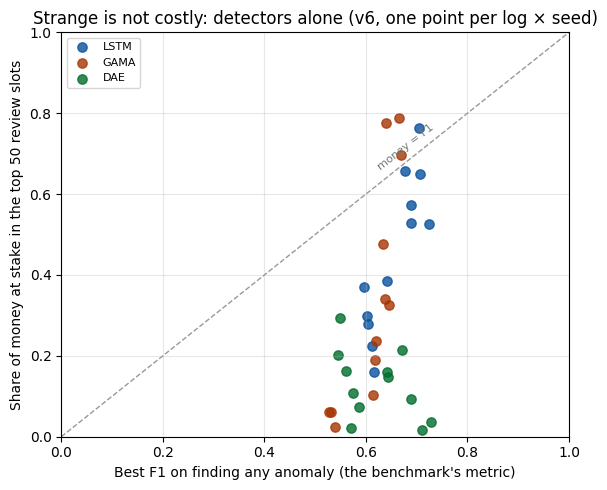

Saved: /content/drive/MyDrive/FCA_PAD_v2/23_hypothesis_tests


In [ ]:
# 6 · Figure for H1: high F1, little money
import matplotlib.pyplot as plt
if F1.empty:
    print("H1 figure skipped: no usable v6 results (see the messages printed in step 2).")
else:
  fig, ax = plt.subplots(figsize=(6, 5))
  for det, c in zip(DETECTORS, ["#08519c", "#a63603", "#006d2c"]):
      x = F1[F1.detector == det]
      ax.scatter(x["best_F1_any_anomaly"], x[MR], s=45, color=c, label=det, alpha=.8)
  ax.plot([0, 1], [0, 1], ls="--", color="#999", lw=1)
  ax.text(0.62, 0.66, "money = F1", color="#777", fontsize=8, rotation=38)
  ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.grid(alpha=.3); ax.legend(fontsize=8)
  ax.set_xlabel("Best F1 on finding any anomaly (the benchmark's metric)")
  ax.set_ylabel(f"Share of money at stake in the top {K} review slots")
  ax.set_title("Strange is not costly: detectors alone (v6, one point per log × seed)")
  plt.tight_layout(); plt.savefig(f"{OUT}/H1_f1_vs_money.png", dpi=150); plt.show()
  print("Saved:", OUT)
